<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/G03_U2_2_eda_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Check the contents of My Drive
import os

print(os.listdir('/content/drive/MyDrive'))

['CSC4110_G03']


In [3]:
# Check whether the shared project folder is accessible
import os

print(os.listdir('/content/drive/MyDrive'))

['CSC4110_G03']


In [4]:
# Import the libraries needed for data analysis
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the project and data folder paths
PROJECT_DIR = "/content/drive/MyDrive/CSC4110_G03"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

# Create the outputs folder if it does not exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Check whether the dataset exists
file_path = os.path.join(DATA_DIR, "stage1_crops.csv")
print("Dataset exists:", os.path.exists(file_path))

# Load the dataset
df_stage1 = pd.read_csv(file_path)

# Display the first five rows and dataset dimensions
display(df_stage1.head())
print("Dataset shape:", df_stage1.shape)

Dataset exists: True


,Area,Item,Year,yield_hg_ha,rain_mm,pesticides_t,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


Dataset shape: (25932, 7)


In [5]:
# Check that all crop yield values are positive
print("Minimum crop yield:", df_stage1["yield_hg_ha"].min())

# Create a logarithmic transformation of crop yield
df_stage1["log_yield"] = np.log(df_stage1["yield_hg_ha"])

# Display the original and transformed values
display(df_stage1[["yield_hg_ha", "log_yield"]].head())

Minimum crop yield: 50


,yield_hg_ha,log_yield
0,36613,10.508159
1,66667,11.107465
2,23333,10.057624
3,12500,9.433484
4,7000,8.853665


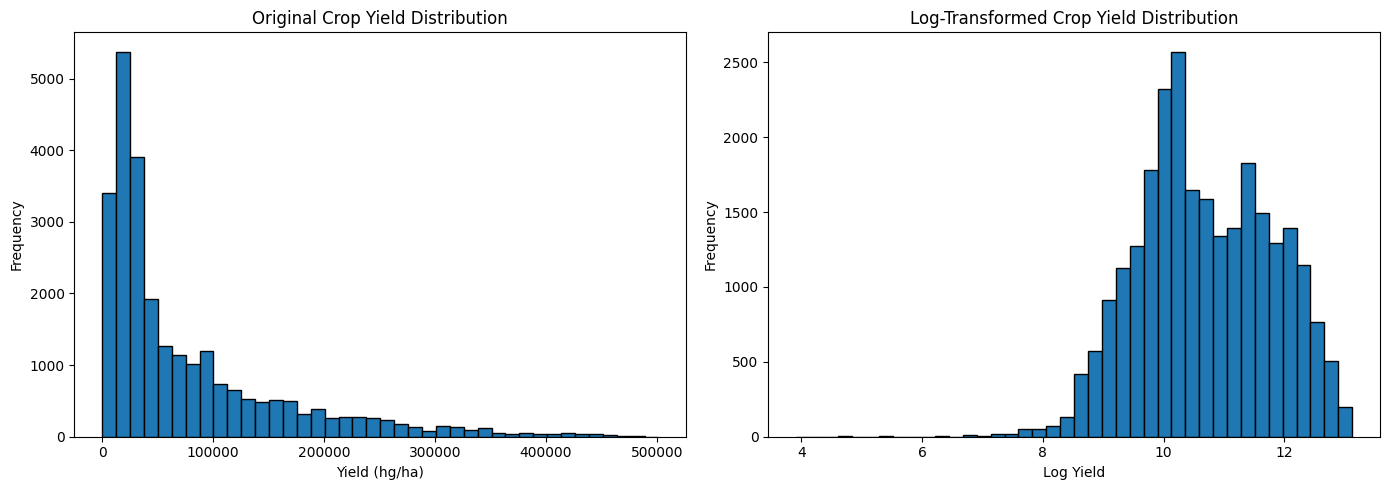

In [6]:
# Compare the distribution of original and logarithmic crop yield
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot original crop yield
axes[0].hist(df_stage1["yield_hg_ha"], bins=40, edgecolor="black")
axes[0].set_title("Original Crop Yield Distribution")
axes[0].set_xlabel("Yield (hg/ha)")
axes[0].set_ylabel("Frequency")

# Plot logarithmic crop yield
axes[1].hist(df_stage1["log_yield"], bins=40, edgecolor="black")
axes[1].set_title("Log-Transformed Crop Yield Distribution")
axes[1].set_xlabel("Log Yield")
axes[1].set_ylabel("Frequency")

# Display both plots
plt.tight_layout()
plt.show()

In [7]:
# Create a working copy for transformation
df_clean = df_stage1.copy()

# Replace each country with its frequency in the dataset
area_frequency = df_clean["Area"].value_counts(normalize=True)
df_clean["Area_frequency"] = df_clean["Area"].map(area_frequency)

# Remove the original Area column
df_clean.drop(columns=["Area"], inplace=True)

# One-hot encode the Item column
item_encoded = pd.get_dummies(
    df_clean["Item"],
    prefix="Item",
    dtype=int
)

# Add the encoded crop columns
df_clean = pd.concat([df_clean, item_encoded], axis=1)

# Create years since 1990
df_clean["years_since_1990"] = df_clean["Year"] - 1990

# Display the transformed dataset
display(df_clean.head())

# Check the new columns and dimensions
print("New dataset shape:", df_clean.shape)
print("\nEncoded crop columns:")
print(item_encoded.columns.tolist())

,Item,Year,yield_hg_ha,rain_mm,pesticides_t,avg_temp,log_yield,Area_frequency,Item_Cassava,Item_Maize,Item_Plantains and others,Item_Potatoes,"Item_Rice, paddy",Item_Sorghum,Item_Soybeans,Item_Sweet potatoes,Item_Wheat,Item_Yams,years_since_1990
0,Maize,1990,36613,1485.0,121.0,16.37,10.508159,0.003818,0,1,0,0,0,0,0,0,0,0,0
1,Potatoes,1990,66667,1485.0,121.0,16.37,11.107465,0.003818,0,0,0,1,0,0,0,0,0,0,0
2,"Rice, paddy",1990,23333,1485.0,121.0,16.37,10.057624,0.003818,0,0,0,0,1,0,0,0,0,0,0
3,Sorghum,1990,12500,1485.0,121.0,16.37,9.433484,0.003818,0,0,0,0,0,1,0,0,0,0,0
4,Soybeans,1990,7000,1485.0,121.0,16.37,8.853665,0.003818,0,0,0,0,0,0,1,0,0,0,0


New dataset shape: (25932, 19)

Encoded crop columns:
['Item_Cassava', 'Item_Maize', 'Item_Plantains and others', 'Item_Potatoes', 'Item_Rice, paddy', 'Item_Sorghum', 'Item_Soybeans', 'Item_Sweet potatoes', 'Item_Wheat', 'Item_Yams']


In [8]:
# Save the cleaned and transformed dataset
clean_file = os.path.join(DATA_DIR, "clean_crops.csv")
df_clean.to_csv(clean_file, index=False)

print("Dataset saved successfully:", clean_file)

Dataset saved successfully: /content/drive/MyDrive/CSC4110_G03/data/clean_crops.csv


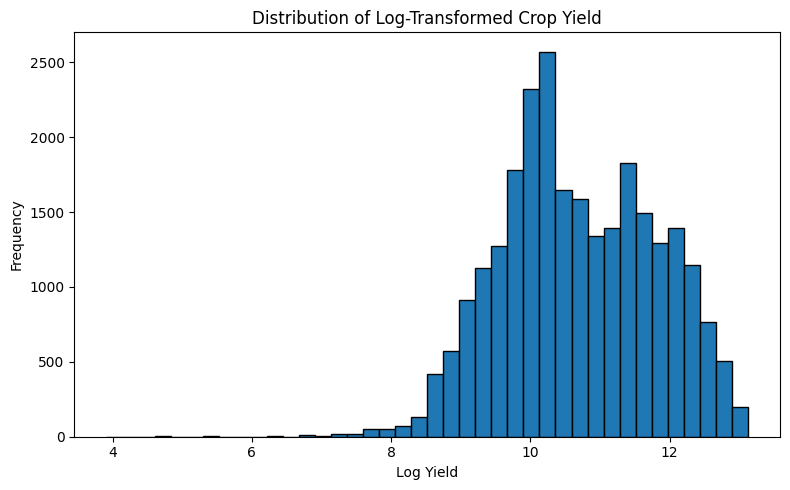

In [9]:
# Plot and save the histogram of log_yield
plt.figure(figsize=(8, 5))
plt.hist(df_clean["log_yield"], bins=40, edgecolor="black")
plt.title("Distribution of Log-Transformed Crop Yield")
plt.xlabel("Log Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "hist_target.png"))
plt.show()

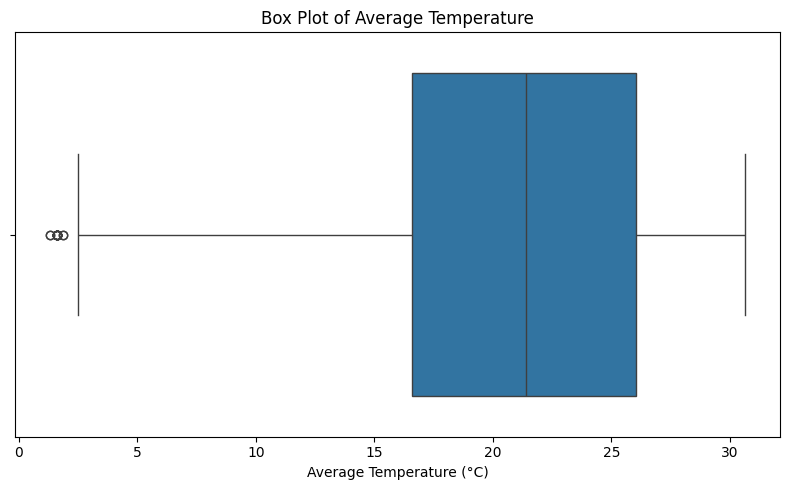

In [10]:
# Plot and save the box plot of average temperature
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_clean["avg_temp"])
plt.title("Box Plot of Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "box_feature.png"))
plt.show()

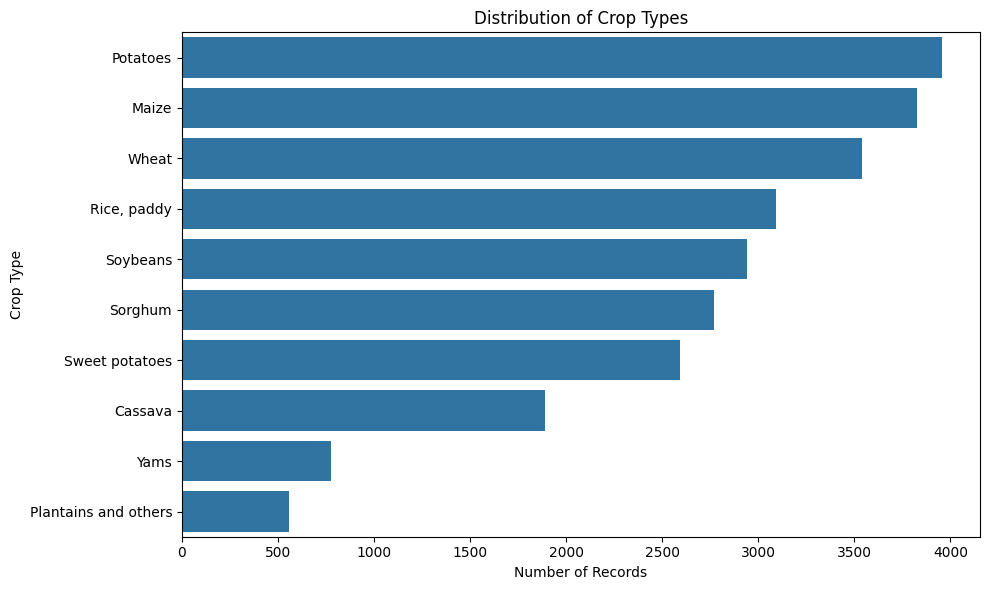

In [11]:
# Plot and save the crop type distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, y="Item", order=df_clean["Item"].value_counts().index)
plt.title("Distribution of Crop Types")
plt.xlabel("Number of Records")
plt.ylabel("Crop Type")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "bar_class.png"))
plt.show()

Best numeric predictor: pesticides_t
Correlation: 0.13917357082296478


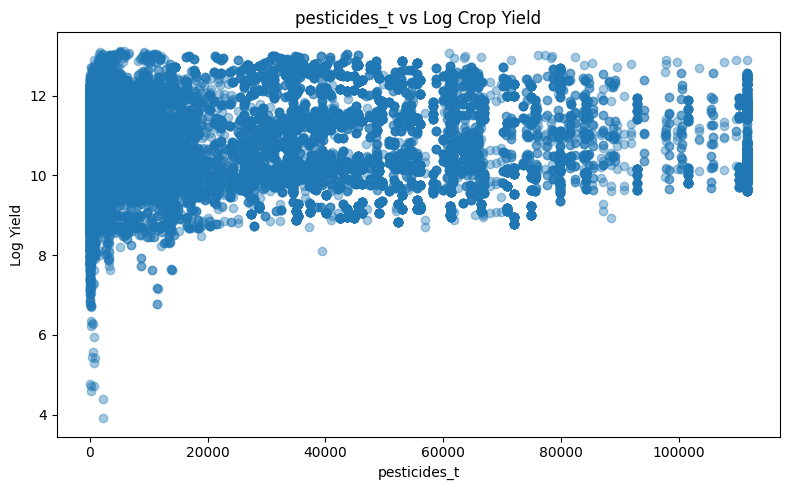

In [12]:
# Identify the numeric predictor most correlated with log_yield
numeric_features = [
    "rain_mm", "pesticides_t", "avg_temp",
    "years_since_1990", "Area_frequency"
]

correlations = df_clean[numeric_features + ["log_yield"]].corr()
best_predictor = correlations["log_yield"].drop("log_yield").abs().idxmax()

print("Best numeric predictor:", best_predictor)
print("Correlation:", correlations.loc[best_predictor, "log_yield"])

# Plot and save the scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df_clean[best_predictor], df_clean["log_yield"], alpha=0.4)
plt.title(f"{best_predictor} vs Log Crop Yield")
plt.xlabel(best_predictor)
plt.ylabel("Log Yield")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "scatter_best.png"))
plt.show()

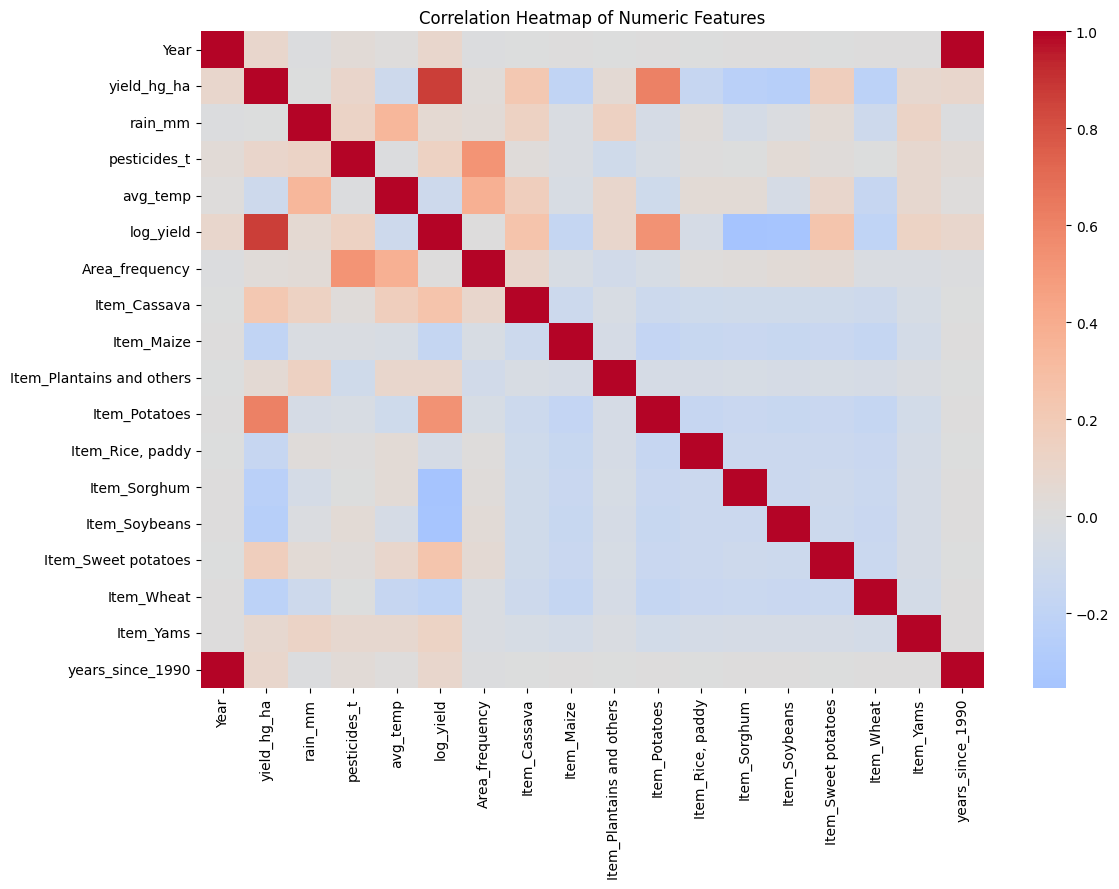

In [13]:
# Plot and save the correlation heatmap
numeric_data = df_clean.select_dtypes(include=np.number)

plt.figure(figsize=(12, 9))
sns.heatmap(numeric_data.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "corr_heatmap.png"))
plt.show()

In [14]:
# Import the scaling methods
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Create the two scalers
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

# Apply both scaling methods to rainfall
rainfall = df_clean[["rain_mm"]]

rain_minmax = minmax_scaler.fit_transform(rainfall)
rain_standard = standard_scaler.fit_transform(rainfall)

# Display the first five values for comparison
scaling_comparison = pd.DataFrame({
    "Original Rainfall": rainfall["rain_mm"].head(5),
    "Min-Max Scaled": rain_minmax[:5].flatten(),
    "Standard Scaled": rain_standard[:5].flatten()
})

display(scaling_comparison)

,Original Rainfall,Min-Max Scaled,Standard Scaled
0,1485.0,0.449671,0.471388
1,1485.0,0.449671,0.471388
2,1485.0,0.449671,0.471388
3,1485.0,0.449671,0.471388
4,1485.0,0.449671,0.471388


In [15]:
# Separate the regression target from the input features
y = df_clean["log_yield"]

# Remove target, original yield, and non-numeric categorical/time columns
X = df_clean.drop(columns=[
    "log_yield",
    "yield_hg_ha",
    "Item",
    "Year"
])

# Display the feature and target dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (25932, 15)
Target shape: (25932,)


In [16]:
# Import the standard scaler
from sklearn.preprocessing import StandardScaler

# Identify training and testing years
train_mask = df_clean["Year"] <= 2009
test_mask = (df_clean["Year"] >= 2010) & (df_clean["Year"] <= 2013)

# Split the features and target by year
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Create the scaler and fit it using training data only
scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

# Transform test data using the already fitted scaler
X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

# Display the split results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining years:", df_clean.loc[train_mask, "Year"].min(),
      "to", df_clean.loc[train_mask, "Year"].max())

print("Testing years:", df_clean.loc[test_mask, "Year"].min(),
      "to", df_clean.loc[test_mask, "Year"].max())

Training features: (21305, 15)
Testing features: (4627, 15)
Training target: (21305,)
Testing target: (4627,)

Training years: 1990 to 2009
Testing years: 2010 to 2013


The scaler is fitted on the training data only to prevent data leakage. If the scaler uses information from the testing data, it allows the model to indirectly learn from data it has not yet seen during training. This can lead to misleading evaluation results. Therefore, the training data determines the scaling parameters, and the same parameters are applied to the testing data.

In [17]:
# Find the most common crop type
crop_counts = df_clean["Item"].value_counts()
print("Most common crop:", crop_counts.index[0])
print("Number of records:", crop_counts.iloc[0])

# Find the least common crop type
print("\nLeast common crop:", crop_counts.index[-1])
print("Number of records:", crop_counts.iloc[-1])

# Find the strongest numeric predictor of log yield
numeric_features = [
    "rain_mm", "pesticides_t", "avg_temp",
    "years_since_1990", "Area_frequency"
]

correlations = df_clean[numeric_features + ["log_yield"]].corr()
best_predictor = correlations["log_yield"].drop("log_yield").abs().idxmax()

print("\nStrongest numeric predictor:", best_predictor)
print("Correlation with log yield:",
      round(correlations.loc[best_predictor, "log_yield"], 4))

# Display crop yield statistics
print("\nLog yield statistics:")
print(df_clean["log_yield"].describe())

Most common crop: Potatoes
Number of records: 3956

Least common crop: Plantains and others
Number of records: 556

Strongest numeric predictor: pesticides_t
Correlation with log yield: 0.1392

Log yield statistics:
count    25932.000000
mean        10.685462
std          1.107790
min          3.912023
25%          9.903288
50%         10.584815
75%         11.553760
max         13.125183
Name: log_yield, dtype: float64


### EDA Findings and Data Splitting

The dataset contains 25,932 records, with Potatoes being the most common crop type at 3,956 records, while Plantains and others are the least common at 556 records. Pesticides used was the strongest numeric predictor of log yield, although its correlation was relatively weak and positive at 0.1392. The average log yield was 10.6855, while the median was 10.5848, indicating that the distribution has a slightly higher mean than median. The data was divided chronologically, using 21,305 records from 1990–2009 for training and 4,627 records from 2010–2013 for testing. The scaler was fitted only on the training data to prevent data leakage and ensure that information from the testing period does not influence the training process.

In [18]:
# Verify all required output files
required_files = [
    os.path.join(DATA_DIR, "stage1_crops.csv"),
    os.path.join(DATA_DIR, "clean_crops.csv"),
    os.path.join(OUTPUT_DIR, "hist_target.png"),
    os.path.join(OUTPUT_DIR, "box_feature.png"),
    os.path.join(OUTPUT_DIR, "bar_class.png"),
    os.path.join(OUTPUT_DIR, "scatter_best.png"),
    os.path.join(OUTPUT_DIR, "corr_heatmap.png")
]

for file in required_files:
    print(("FOUND: " if os.path.exists(file) else "MISSING: ") + file)

FOUND: /content/drive/MyDrive/CSC4110_G03/data/stage1_crops.csv
FOUND: /content/drive/MyDrive/CSC4110_G03/data/clean_crops.csv
FOUND: /content/drive/MyDrive/CSC4110_G03/outputs/hist_target.png
FOUND: /content/drive/MyDrive/CSC4110_G03/outputs/box_feature.png
FOUND: /content/drive/MyDrive/CSC4110_G03/outputs/bar_class.png
FOUND: /content/drive/MyDrive/CSC4110_G03/outputs/scatter_best.png
FOUND: /content/drive/MyDrive/CSC4110_G03/outputs/corr_heatmap.png
